# ERC circularité · 01 · Classement et priorisation

**Question** : quelles pièces les ateliers consomment-ils, pour quelle valeur, et lesquelles se retrouvent dans les FRU rebutées ?

**Décision éclairée** : la liste courte des pièces et des types de FRU à étudier en premier, celle qui entre dans le classeur de paramètres et dans le modèle de ligne (notebook 05).

**Limites** : la valeur utilisée ici est le MMICV, un coût standard. Il classe les pièces entre elles ; il ne dit pas ce que rapporte un réemploi.

In [1]:
import sys
from pathlib import Path

# Le dossier est celui qui contient le code (erc/) : le parent de notebooks/.
dossier = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "erc" / "__init__.py").is_file()), Path.cwd().parent)
sys.path.insert(0, str(dossier))
import erc
from erc import affichage as aff

ctx = erc.executer(jusqua="classement")

ERC circularité — DÉMONSTRATION (données fictives)


  étape sources       3 artefacts → artefacts/00_sources/


  étape classement   13 artefacts → artefacts/01_classement/


In [2]:
aff.etat(ctx)

DÉMONSTRATION : toutes les données affichées sont fictives. Période : du 01/06/2026 au 01/11/2026, 154 jours extraits. Aucune anomalie de calcul.

## 1. Les pièces consommées, classées par valeur

Une ligne par pièce consommée sur la période, tous ateliers confondus. **MMICV total** = quantité consommée × MMICV unitaire.

**Lecture** : les premières lignes concentrent l'essentiel du coût standard consommé ; ce sont les pièces dont le réemploi mérite d'être chiffré.

**Limites** : le MMICV est un coût standard, une référence provisoire : ni un prix de revente, ni une valeur de réemploi ; sa devise reste à confirmer. Une pièce sans MMICV connu garde une valeur vide et n'est pas classée (elle n'est pas comptée à zéro). Le type de déchet, la benne et le poids viennent du classement matière, avec son niveau de preuve.

**Top MMICV.** Les pièces consommées classées par MMICV total (quantité × coût standard). Lecture : plus la barre est longue, plus la pièce pèse dans le coût standard consommé ; ce n'est pas ce que rapporterait son réemploi.

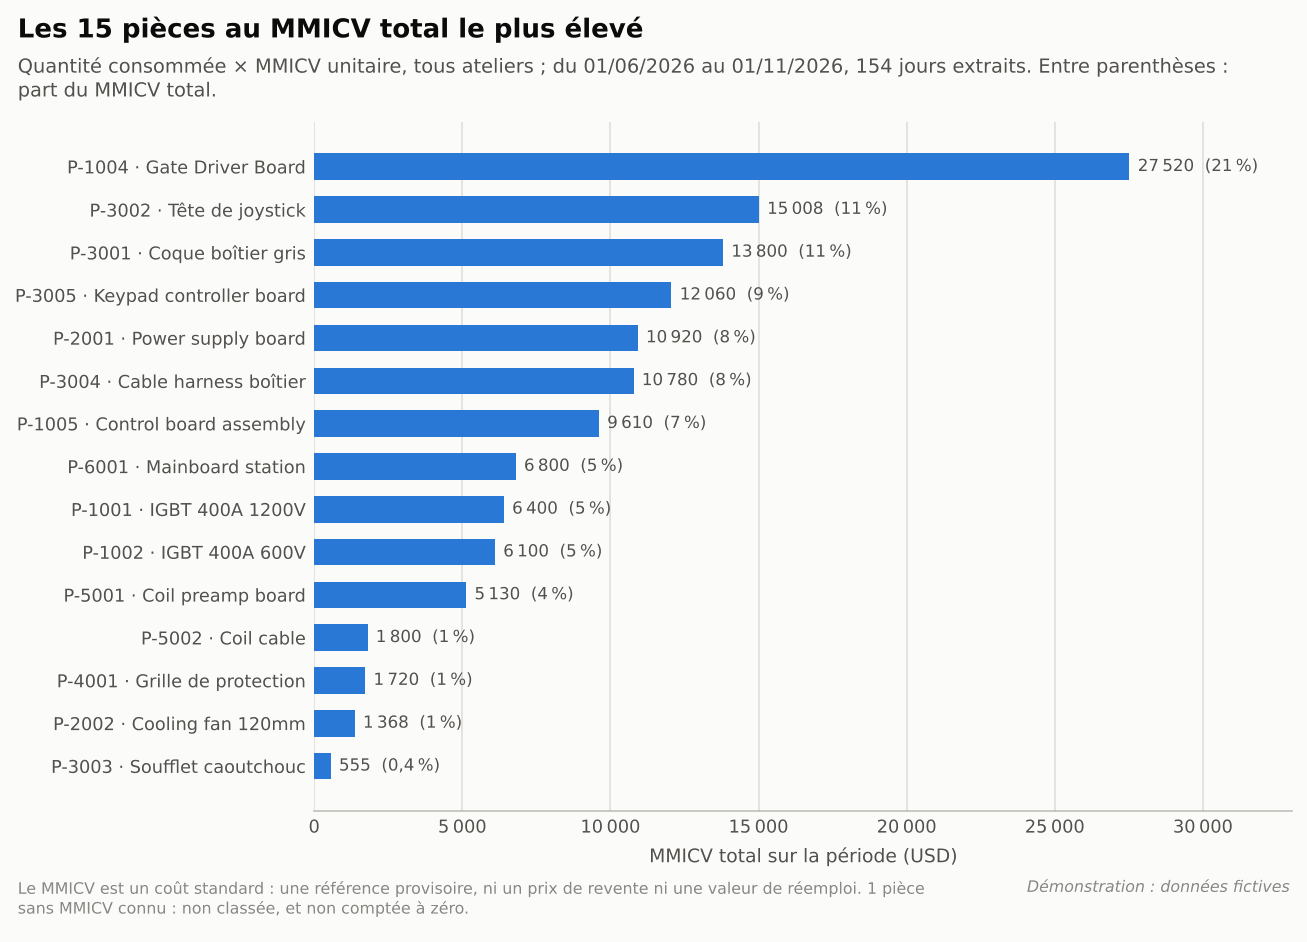

In [3]:
aff.figures(ctx, "classement", "Top MMICV")

In [4]:
aff.table(ctx, "classement", "Classement tous ateliers", colonnes=["Référence", "Description", "Ateliers", "Pièces", "PO", "MMICV unitaire (USD)",
          "Source MMICV", "MMICV total (USD)", "Part du MMICV total", "Catégorie proposée", "Benne", "Poids unitaire (kg)", "Niveau de preuve"])

Référence,Description,Ateliers,Pièces,PO,MMICV unitaire (USD),Source MMICV,MMICV total (USD),Part du MMICV total,Catégorie proposée,Benne,Poids unitaire (kg),Niveau de preuve
P-1004,Gate Driver Board,MR,86,86,"320,0",fiche article,27 520,"21,0 %",Carte B,DEEE,"0,400",démo
P-3002,Tête de joystick,TSUI,268,228,"56,0",fiche article,15 008,"11,5 %",Plastique,DIB,"0,050",démo
P-3001,Coque boîtier gris,TSUI,115,115,"120,0",fiche article,13 800,"10,5 %",Plastique,DIB,"0,600",démo
P-3005,Keypad controller board,TSUI,67,67,"180,0",fiche article,12 060,"9,2 %",Carte C,DEEE,"0,200",démo
P-2001,Power supply board,MR,52,52,"210,0",fiche article,10 920,"8,3 %",Carte B,DEEE,"0,600",démo
P-3004,Cable harness boîtier,TSUI,77,77,"140,0",fiche article,10 780,"8,2 %",Câbles,DEEE,"0,300",démo
P-1005,Control board assembly,MR,31,31,"310,0",fiche article,9 610,"7,3 %",Carte B,DEEE,"0,450",démo
P-6001,Mainboard station,(non rattaché),17,17,"400,0",fiche article,6 800,"5,2 %",,,,
P-1001,IGBT 400A 1200V,MR,200,100,"32,0",fiche article,6 400,"4,9 %",Composant de puissance,DEEE,"0,350",démo
P-1002,IGBT 400A 600V,MR,244,122,"25,0",fiche article,6 100,"4,7 %",Composant de puissance,DEEE,"0,350",démo


Le même classement, limité à chaque atelier prioritaire (dix premières lignes) :

In [5]:
for atelier in ctx.cfg.ateliers_prioritaires:
    display(aff.table(ctx, "classement", f"Classement {atelier}", n=10, colonnes=["Référence", "Description", "Pièces", "MMICV unitaire (USD)", "MMICV total (USD)", "Part du MMICV total"]))

Référence,Description,Pièces,MMICV unitaire (USD),MMICV total (USD),Part du MMICV total
P-1004,Gate Driver Board,86,"320,0",27 520,"44,0 %"
P-2001,Power supply board,52,"210,0",10 920,"17,4 %"
P-1005,Control board assembly,31,"310,0",9 610,"15,3 %"
P-1001,IGBT 400A 1200V,200,"32,0",6 400,"10,2 %"
P-1002,IGBT 400A 600V,244,"25,0",6 100,"9,7 %"
P-2002,Cooling fan 120mm,76,"18,0",1 368,"2,2 %"
P-1006,Bus resistance 33k ohm 10W,119,"4,5",536,"0,9 %"
P-1007,Protection fuse 100A high speed,90,"1,8",162,"0,3 %"
P-1003,AL Electrolytic Capacitor 450V 4700uF 105degC,277,,,


Référence,Description,Pièces,MMICV unitaire (USD),MMICV total (USD),Part du MMICV total
P-3002,Tête de joystick,268,"56,0",15 008,"27,8 %"
P-3001,Coque boîtier gris,115,"120,0",13 800,"25,6 %"
P-3005,Keypad controller board,67,"180,0",12 060,"22,4 %"
P-3004,Cable harness boîtier,77,"140,0",10 780,"20,0 %"
P-4001,Grille de protection,43,"40,0",1 720,"3,2 %"
P-3003,Soufflet caoutchouc,370,"1,5",555,"1,0 %"


## 2. La période est-elle complète ? Les chiffres annoncés tiennent-ils ?

Avant de discuter de valeur, se mettre d'accord sur les volumes. La première table dit, mois par mois, combien de jours sont couverts par les extractions : **un mois incomplet n'est jamais comparé à un chiffre mensuel**. La seconde compare les chiffres annoncés en réunion (saisis dans l'onglet `Chiffres_a_verifier` du classeur de paramètres) aux pièces réellement sorties chaque mois complet.

**Lecture** : un écart négatif signifie que les extractions montrent moins de pièces que le chiffre annoncé. **Limite** : la comparaison cherche un motif dans la description des pièces ; vérifier la colonne « Références » pour s'assurer que les bonnes pièces sont comptées.

In [6]:
aff.table(ctx, "classement", "Mois calendrier")

Mois,Jours extraits,Jours du mois,Mois complet
2026-06,30,30,oui
2026-07,31,31,oui
2026-08,31,31,oui
2026-09,30,30,oui
2026-10,31,31,oui
2026-11,1,30,non


In [7]:
aff.table(ctx, "classement", "Chiffres à vérifier")

Chiffre,Annoncé par mois,Mois,Jours extraits,Mois complet,Pièces observées,Écart,Références
"IGBT, toutes références (chiffre annoncé en revue, démo)",150,2026-06,30,oui,88,−62,"P-1001, P-1002"
"IGBT, toutes références (chiffre annoncé en revue, démo)",150,2026-07,31,oui,74,−76,"P-1001, P-1002"
"IGBT, toutes références (chiffre annoncé en revue, démo)",150,2026-08,31,oui,88,−62,"P-1001, P-1002"
"IGBT, toutes références (chiffre annoncé en revue, démo)",150,2026-09,30,oui,120,−30,"P-1001, P-1002"
"IGBT, toutes références (chiffre annoncé en revue, démo)",150,2026-10,31,oui,74,−76,"P-1001, P-1002"


## 3. Les FRU rebutées : le gisement

FRU rebutées sur la période, par type, avec leur poids. C'est le gisement que la ligne de démontage et de tri aurait à traiter.

**Lecture** : masse rebutée = nombre de FRU × poids de la fiche du FRU ; elle reste vide si le poids est inconnu. **Limite** : la date qui fait entrer un FRU dans la période dépend d'une règle à confirmer ; elle est rappelée dans les notes en fin de notebook.

In [8]:
aff.table(ctx, "classement", "FRU rebutées")

Atelier,FRU,Description FRU,FRU rebutées,Poids FRU (kg),Masse rebutée (kg)
MR,FRU-A100-R,Amplificateur de gradient (démo),132,"79,00",10 428
MR,FRU-A200-R,Alimentation de puissance (démo),49,"62,00",3 038
TSUI,FRU-B300-R,Boîtier de commande (démo),40,"5,50",220
Coils,FRU-C500-R,Antenne de surface (démo),31,"3,00",93
TSUI,FRU-B400-R,Pupitre de table (démo),15,"6,30",94
(non rattaché),FRU-W600-R,Station de travail (démo),6,"11,00",66


## 4. Quelles pièces dans quels FRU ?

Par couple (type de FRU, pièce), ce que montrent les consommations en réparation :

- **Réparations du FRU** : nombre d'ordres de réparation de ce type de FRU qui ont consommé au moins une pièce ;
- **Part des réparations** : part de ces réparations où la pièce a été changée ;
- **Pièces consommées** et **Réparations du FRU** : la base de la probabilité de défaut utilisée par le modèle de Rex (notebook 04) ;
- **Max par PO** : la plus grande quantité de la pièce consommée sur une même réparation.

**Limite essentielle** : le nombre de pièces par FRU est **inconnu avant un audit de démontage**. « Max par PO » n'est qu'un minimum : un FRU peut contenir quatre exemplaires d'une pièce dont on n'a jamais changé plus de deux à la fois.

In [9]:
aff.table(ctx, "classement", "Couples FRU x pièce")

FRU,Pièce,Description,Atelier,Pièces consommées,PO avec la pièce,Réparations du FRU,Part des réparations,Max par PO,Pièces par PO concerné
FRU-A100-R,P-1003,AL Electrolytic Capacitor 450V 4700uF 105degC,MR,277,175,249,"70,3 %",4,"1,58"
FRU-A100-R,P-1001,IGBT 400A 1200V,MR,200,100,249,"40,2 %",2,"2,00"
FRU-A100-R,P-1002,IGBT 400A 600V,MR,170,85,249,"34,1 %",2,"2,00"
FRU-A100-R,P-1006,Bus resistance 33k ohm 10W,MR,119,103,249,"41,4 %",2,"1,16"
FRU-A100-R,P-1004,Gate Driver Board,MR,86,86,249,"34,5 %",1,"1,00"
FRU-A100-R,P-1007,Protection fuse 100A high speed,MR,55,53,249,"21,3 %",2,"1,04"
FRU-A100-R,P-1005,Control board assembly,MR,31,31,249,"12,4 %",1,"1,00"
FRU-A200-R,P-2002,Cooling fan 120mm,MR,76,63,110,"57,3 %",2,"1,21"
FRU-A200-R,P-1002,IGBT 400A 600V,MR,74,37,110,"33,6 %",2,"2,00"
FRU-A200-R,P-2001,Power supply board,MR,52,52,110,"47,3 %",1,"1,00"


La table suivante retourne la question : pour chaque pièce, combien de FRU rebutées l'ont dans leur nomenclature de consommation.

In [10]:
aff.table(ctx, "classement", "Composants des FRU rebutées")

Référence,Description,FRU rebutées qui l'ont dans leur nomenclature,FRU concernées,Ateliers,Pièces consommées sur la période,MMICV unitaire (USD),Minimum de pièces par FRU (max observé par PO)
P-3003,Soufflet caoutchouc,40,FRU-B300-R,TSUI,370,"1,5",2
P-1003,AL Electrolytic Capacitor 450V 4700uF 105degC,132,FRU-A100-R,MR,277,,4
P-3002,Tête de joystick,55,"FRU-B300-R, FRU-B400-R",TSUI,268,"56,0",2
P-1002,IGBT 400A 600V,181,"FRU-A100-R, FRU-A200-R",MR,244,"25,0",2
P-1001,IGBT 400A 1200V,132,FRU-A100-R,MR,200,"32,0",2
P-1006,Bus resistance 33k ohm 10W,132,FRU-A100-R,MR,119,"4,5",2
P-3001,Coque boîtier gris,40,FRU-B300-R,TSUI,115,"120,0",1
P-1007,Protection fuse 100A high speed,181,"FRU-A100-R, FRU-A200-R",MR,90,"1,8",2
P-1004,Gate Driver Board,132,FRU-A100-R,MR,86,"320,0",1
P-3004,Cable harness boîtier,40,FRU-B300-R,TSUI,77,"140,0",1


## 5. Pré-sélection des pièces

Chaque pièce est décrite par plusieurs critères, sans pondération imposée :

- **valeur** : MMICV total consommé ;
- **gisement** : FRU rebutées dont la nomenclature contient la pièce ;
- **risque matière** (0 à 1) : présence de matières premières critiques ou stratégiques selon le type de pièce reconnu dans sa description ;
- **risque d'approvisionnement** (0 à 1) : tiré du délai fourni par les achats (onglet `Supply`), sinon d'une valeur par défaut selon le type de pièce ;
- **fiabilité du réemploi** : ajoutée au notebook 03, quand le fichier de fiabilité le permet.

Une pièce est **sur le front de Pareto** quand aucune autre ne fait au moins aussi bien sur tous les critères et mieux sur au moins un : ce sont les candidates à examiner en premier. Une pièce sans donnée sur un critère y est classée au plus bas. La « note à poids égaux » n'est qu'indicative.

**Limites** : le risque matière repose sur une composition qualitative par type de pièce (présence, pas de teneur), à confirmer par la fiche matière du fabricant. Un critère sans donnée est laissé de côté ; les notes disent lesquels sont actifs.

**Pré-sélection.** Chaque point est une pièce : en abscisse le nombre de FRU rebutées qui la contiennent (gisement), en ordonnée son MMICV total consommé (valeur). Les points bleus forment le front de Pareto : ce sont les candidates à examiner en premier.

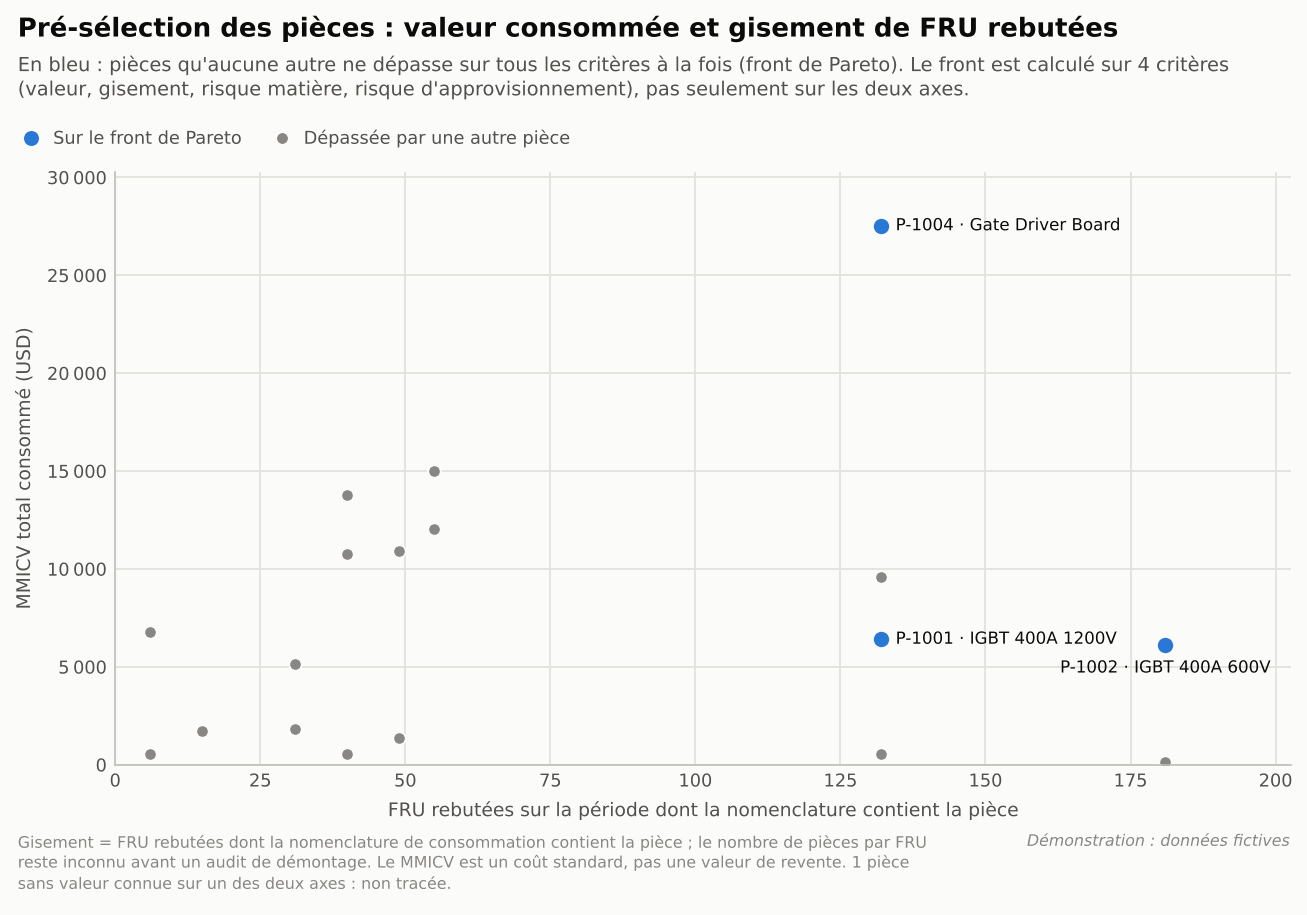

In [11]:
aff.figures(ctx, "classement", "Pré-sélection")

In [12]:
aff.table(ctx, "classement", "Priorisation", colonnes=["Référence", "Description", "Sur le front de Pareto", "MMICV total (USD)", "FRU rebutées (nomenclature)",
          "Score risque matière (0-1)", "Risque supply retenu", "Source supply retenue", "Note (poids égaux, indicatif)", "Type de pièce", "CRM", "Ateliers"])

Référence,Description,Sur le front de Pareto,MMICV total (USD),FRU rebutées (nomenclature),Score risque matière (0-1),Risque supply retenu,Source supply retenue,"Note (poids égaux, indicatif)",Type de pièce,CRM,Ateliers
P-1004,Gate Driver Board,oui,27 520,132,"1,00","0,62",délai fourni par les achats,"0,836",Carte électronique,"cuivre, platinoïdes (PGM), tantale, gallium, antimoine",MR
P-1001,IGBT 400A 1200V,oui,6 400,132,"0,75","1,00",délai fourni par les achats,"0,735",IGBT / module de puissance,"cuivre, bauxite/alumine/aluminium, silicium métal",MR
P-1002,IGBT 400A 600V,oui,6 100,181,"0,75","1,00",délai fourni par les achats,"0,767",IGBT / module de puissance,"cuivre, bauxite/alumine/aluminium, silicium métal",MR
P-3002,Tête de joystick,non,15 008,55,"0,00",,aucune,"0,420",Pièce plastique / mécanique,,TSUI
P-3001,Coque boîtier gris,non,13 800,40,"0,00",,aucune,"0,347",Pièce plastique / mécanique,,TSUI
P-3005,Keypad controller board,non,12 060,55,"1,00","0,38",délai fourni par les achats,"0,608",Carte électronique,"cuivre, platinoïdes (PGM), tantale, gallium, antimoine",TSUI
P-2001,Power supply board,non,10 920,49,"1,00","0,46",délai fourni par les achats,"0,599",Carte électronique,"cuivre, platinoïdes (PGM), tantale, gallium, antimoine",MR
P-3004,Cable harness boîtier,non,10 780,40,"0,25",,aucune,"0,358",Câble / faisceau,cuivre,TSUI
P-1005,Control board assembly,non,9 610,132,"1,00","0,62",délai fourni par les achats,"0,753",Carte électronique,"cuivre, platinoïdes (PGM), tantale, gallium, antimoine",MR
P-6001,Mainboard station,non,6 800,6,"1,00","0,60",a priori de type,"0,499",Carte électronique,"cuivre, platinoïdes (PGM), tantale, gallium, antimoine",(non rattaché)


## Notes de l'étape

Source des FRU rebutées, critères actifs et inactifs, création du classeur de paramètres.

In [13]:
aff.notes(ctx, "classement")

Élément,Valeur
Source des FRU rebutées,"onglet FRU_rebutees des extractions ; date de rebut : plus tardive des dates de la ligne (Date creation PO, Date reception, Date diagnostic, Date statut) : à confirmer"
Classeur de paramètres créé à cette exécution,non
Critères actifs,"MMICV total (USD), FRU rebutées (nomenclature), Score risque matière (0-1), Risque supply retenu"
Critères inactifs faute de données,Fiabilité réemploi (1/rapport)


---
Notebook suivant : **02_Flux_entree**. Tous les fichiers affichés ici sont dans le dossier des artefacts, étape `01_classement` ; un classeur Excel du même nom réunit les tables de l'étape.